In [1]:
!pip install catboost xgboost lightgbm gradio

# Task 04 — Adult Census Income (Classification)
**Goal:** predict whether a person earns more than 50K a year. **Target:** `income` (1 = `>50K`). **Features:** age, workclass, education.num, marital.status, occupation, relationship, race, sex, capital.gain, capital.loss, hours.per.week, native.country (`education` is dropped because `education.num` is the same information, `fnlwgt` is a census sampling weight).

**Imbalance:** about 24% of the people earn `>50K` (moderately imbalanced), so Accuracy alone is not enough (always predicting `<=50K` already gives ~76%). We also look at **Precision, Recall, F1, ROC-AUC and PR-AUC**.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

## 1. Load the data

In [3]:
import os
path = 'dataset/Adult_Census_Income.csv'
if not os.path.exists(path):          # e.g. file uploaded next to the notebook (Colab)
    path = 'Adult_Census_Income.csv'
df = pd.read_csv(path)

In [4]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [5]:
df.shape

(32561, 15)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [7]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [8]:
df.columns

Index(['age', 'workclass', 'fnlwgt', 'education', 'education.num',
       'marital.status', 'occupation', 'relationship', 'race', 'sex',
       'capital.gain', 'capital.loss', 'hours.per.week', 'native.country',
       'income'],
      dtype='object')

## 2. Data cleaning

In [9]:
df.duplicated().sum()

np.int64(24)

In [10]:
df = df.drop_duplicates()

In [11]:
df.duplicated().sum()

np.int64(0)

The file uses `?` for unknown values (workclass, occupation, native.country). They are turned into NaN first.

In [12]:
df = df.replace("?", np.nan)

In [13]:
df.isnull().sum()

,0
age,0
workclass,1836
fnlwgt,0
education,0
education.num,0
marital.status,0
occupation,1843
relationship,0
race,0
sex,0


**Missing values:** the old code filled them with the most frequent value of the whole data before the split. Now they become the category `Unknown` (nothing is learned from the data, so no leakage, and the model can learn that "unknown occupation" is itself informative).

In [14]:
# '?' means "not known": instead of guessing the most frequent value, it becomes its own category 'Unknown'
# (a fixed rule, it learns nothing from the data, so it is safe to do before the split)
for col in ["workclass", "occupation", "native.country"]:
    df[col] = df[col].fillna("Unknown")

In [15]:
df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education.num,0
marital.status,0
occupation,0
relationship,0
race,0
sex,0


### Outliers (IQR rule)

In [16]:
for col in ['age', 'education.num', 'hours.per.week', 'capital.gain', 'capital.loss']:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: {n_out} outliers ({n_out / len(df) * 100:.1f}%)  [valid range {low:.1f} to {high:.1f}]  max = {df[col].max()}")
print("capital.gain = 0 for", round((df['capital.gain'] == 0).mean() * 100), "% of the people")

age: 142 outliers (0.4%)  [valid range -2.0 to 78.0]  max = 90
education.num: 1193 outliers (3.7%)  [valid range 4.5 to 16.5]  max = 16
hours.per.week: 9002 outliers (27.7%)  [valid range 32.5 to 52.5]  max = 99
capital.gain: 2712 outliers (8.3%)  [valid range 0.0 to 0.0]  max = 99999
capital.loss: 1519 outliers (4.7%)  [valid range 0.0 to 0.0]  max = 4356
capital.gain = 0 for 92 % of the people


**Decision:** the outliers are **kept**. Old people, very long working weeks and big capital gains are real values, and high capital gain is exactly a sign of high income. `capital.gain` / `capital.loss` are very skewed (almost everybody has 0), so they get a `log1p` transformation after the split (already in the code below) and all numeric columns are scaled.

## 3. EDA (visualization)

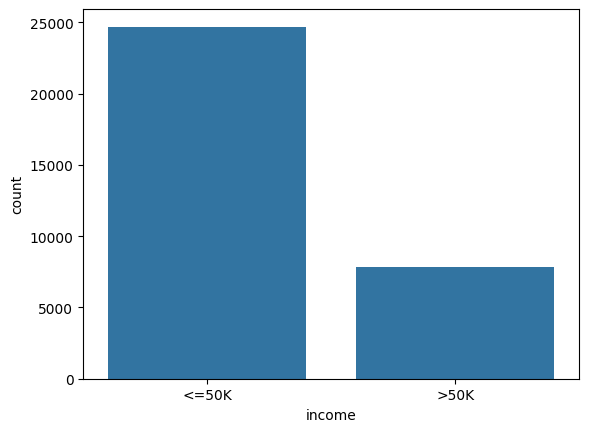

In [17]:
sns.countplot(x="income", data=df)
plt.show()

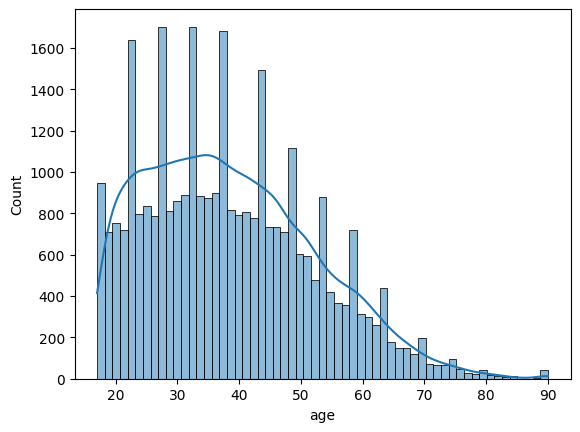

In [18]:
sns.histplot(df["age"], kde=True)
plt.show()

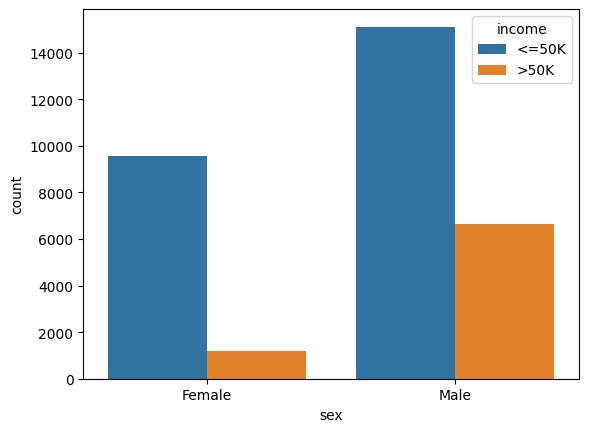

In [19]:
sns.countplot(x="sex", hue="income", data=df)
plt.show()

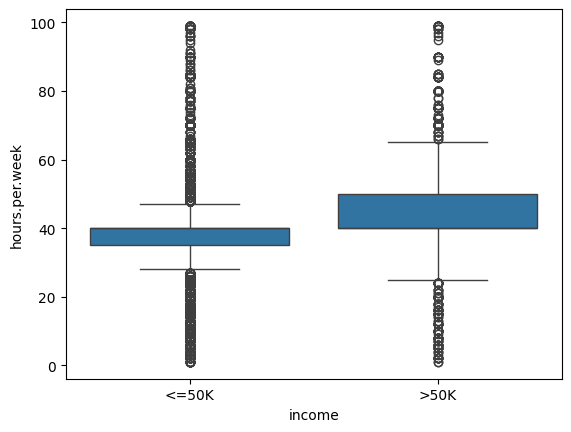

In [20]:
sns.boxplot(x="income", y="hours.per.week", data=df)
plt.show()

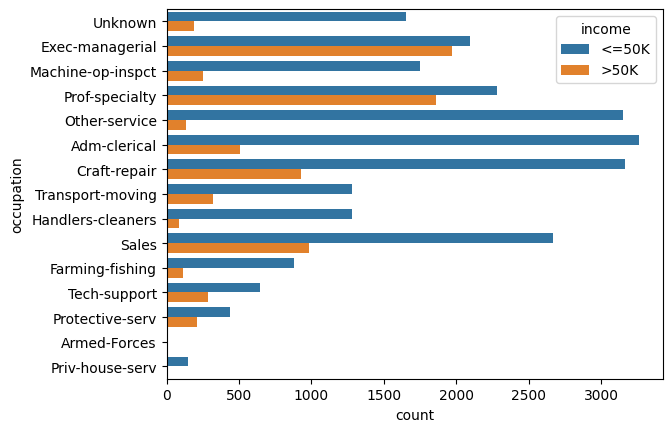

In [21]:
sns.countplot(y="occupation", hue="income", data=df)
plt.show()

## 4. Encoding

In [22]:
df["income"] = df["income"].map({"<=50K": 0, ">50K": 1})
df["sex"] = df["sex"].map({"Female": 0, "Male": 1})

In [23]:
df = df.drop(columns=["education", "fnlwgt"])

In [24]:
df = pd.get_dummies(df, columns=["workclass", "marital.status", "occupation", "relationship", "race"], drop_first=True, dtype=int)

In [25]:
X = df.drop(columns="income")
y = df["income"]

## 5. Train / Test split
Stratified split: the percentage of `>50K` stays the same in train and test.

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("Share of >50K in train / test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

X_train: (26029, 44)  X_test: (6508, 44)
Share of >50K in train / test: 0.241 / 0.241


### Target encoding of `native.country` (the original code, computed from the train data only)
Note: the encoding uses the train labels, so it is a little optimistic inside cross-validation; the test set is never used for it.

In [27]:
country_mean = y_train.groupby(X_train["native.country"]).mean()
X_train["native.country"] = X_train["native.country"].map(country_mean)
X_test["native.country"] = X_test["native.country"].map(country_mean).fillna(y_train.mean())

In [28]:
X_train["capital.gain"] = np.log1p(X_train["capital.gain"])
X_test["capital.gain"] = np.log1p(X_test["capital.gain"])
X_train["capital.loss"] = np.log1p(X_train["capital.loss"])
X_test["capital.loss"] = np.log1p(X_test["capital.loss"])

In [29]:
cols = ["age", "education.num", "capital.gain", "capital.loss", "hours.per.week", "native.country"]
scaler = StandardScaler()
X_train[cols] = scaler.fit_transform(X_train[cols])
X_test[cols] = scaler.transform(X_test[cols])

In [30]:
y_train.value_counts()
results = []
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print("X_train_smote = ", X_train_smote.shape, " y_train_smote = ", y_train_smote.shape)
y_train_smote.value_counts()
rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)
print("X_train_rus = ", X_train_rus.shape, " y_train_rus = ", y_train_rus.shape)

y_train_rus.value_counts()


X_train_smote =  (39516, 44)  y_train_smote =  (39516,)
X_train_rus =  (12542, 44)  y_train_rus =  (12542,)


,count
income,
0,6271
1,6271


## 6. Logistic Regression, KNN and Naive Bayes + handling the imbalance
Normal data, SMOTE (over sampling), random under sampling and class weights.

In [31]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Model': "Logistic Regression",
    'Method': "Normal Data",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [32]:
# Logistic Regression - SMOTE Over Sampling
model = LogisticRegression(max_iter=1000)
model.fit(X_train_smote, y_train_smote)
y_pred = model.predict(X_test)

results.append({
    'Model': "Logistic Regression",
    'Method': "SMOTE Over Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [33]:
# Logistic Regression - Random Under Sampling
model = LogisticRegression(max_iter=1000)
model.fit(X_train_rus, y_train_rus)
y_pred = model.predict(X_test)

results.append({
    'Model': "Logistic Regression",
    'Method': "Random Under Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [34]:
# Logistic Regression - Class Weight Balanced
model = LogisticRegression(max_iter=1000, class_weight='balanced')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Model': "Logistic Regression",
    'Method': "Class Weight Balanced",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [35]:
model = KNeighborsClassifier(n_neighbors=15)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Model': "KNN",
    'Method': "Normal Data",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [36]:
# KNN - SMOTE Over Sampling
model = KNeighborsClassifier(n_neighbors=15)
model.fit(X_train_smote, y_train_smote)
y_pred = model.predict(X_test)

results.append({
    'Model': "KNN",
    'Method': "SMOTE Over Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [37]:
# KNN - Random Under Sampling
model = KNeighborsClassifier(n_neighbors=15)
model.fit(X_train_rus, y_train_rus)
y_pred = model.predict(X_test)

results.append({
    'Model': "KNN",
    'Method': "Random Under Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [38]:
model = GaussianNB(var_smoothing=0.1)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Model': "Naive Bayes",
    'Method': "Normal Data",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [39]:
# Naive Bayes - SMOTE Over Sampling
model = GaussianNB(var_smoothing=0.1)
model.fit(X_train_smote, y_train_smote)
y_pred = model.predict(X_test)

results.append({
    'Model': "Naive Bayes",
    'Method': "SMOTE Over Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [40]:
# Naive Bayes - Random Under Sampling
model = GaussianNB(var_smoothing=0.1)
model.fit(X_train_rus, y_train_rus)
y_pred = model.predict(X_test)

results.append({
    'Model': "Naive Bayes",
    'Method': "Random Under Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

In [41]:
results_df = pd.DataFrame(results).set_index(['Model', 'Method'])
results_df.round(3)

Accuracy  Precision  Recall  \
Model               Method                                               
Logistic Regression Normal Data               0.845      0.715   0.593   
                    SMOTE Over Sampling       0.808      0.574   0.796   
                    Random Under Sampling     0.801      0.559   0.825   
                    Class Weight Balanced     0.803      0.562   0.825   
KNN                 Normal Data               0.837      0.671   0.639   
                    SMOTE Over Sampling       0.784      0.533   0.833   
                    Random Under Sampling     0.784      0.533   0.857   
Naive Bayes         Normal Data               0.770      0.514   0.829   
                    SMOTE Over Sampling       0.730      0.469   0.897   
                    Random Under Sampling     0.739      0.478   0.888   

                                           F1-Score  
Model               Method                           
Logistic Regression Normal Data               0.648  
                    SMOTE Over Sampling       0.667  
                    Random Under Sampling     0.667  
                    Class Weight Balanced     0.669  
KNN                 Normal Data               0.654  
                    SMOTE Over Sampling       0.650  
                    Random Under Sampling     0.657  
Naive Bayes         Normal Data               0.635  
                    SMOTE Over Sampling       0.616  
                    Random Under Sampling     0.621

**Reading the table:** with a moderate imbalance, the sampling methods trade some precision for more recall; Accuracy changes little. Which method is best depends on the goal: if missing a high earner is costly we want recall, if false alarms are costly we want precision. F1 is the compromise.

## 7. All the models
All models of the track are trained on the prepared data and evaluated on the test set (confusion matrix, classification report, ROC curve, PR curve).

In [42]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[4569  371]
 [ 638  930]]


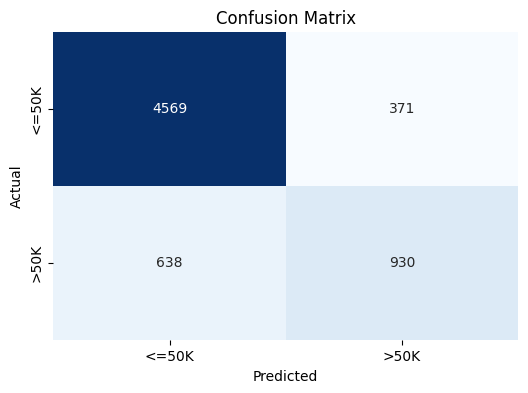


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.88      0.92      0.90      4940
        >50K       0.71      0.59      0.65      1568

    accuracy                           0.84      6508
   macro avg       0.80      0.76      0.77      6508
weighted avg       0.84      0.84      0.84      6508

ROC-AUC: 0.8953417412005287


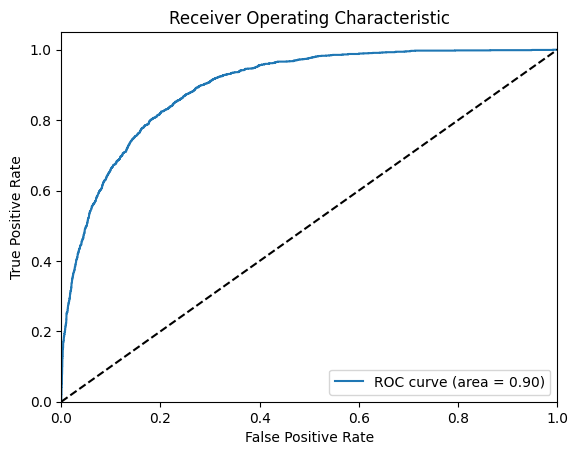

PR AUC: 0.7371389633749352


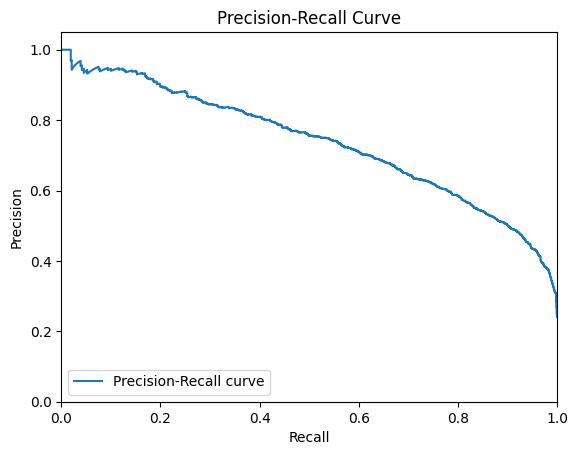

  8%|▊         | 1/13 [00:02<00:35,  2.96s/it]


Confusion Matrix:
 [[4416  524]
 [ 603  965]]


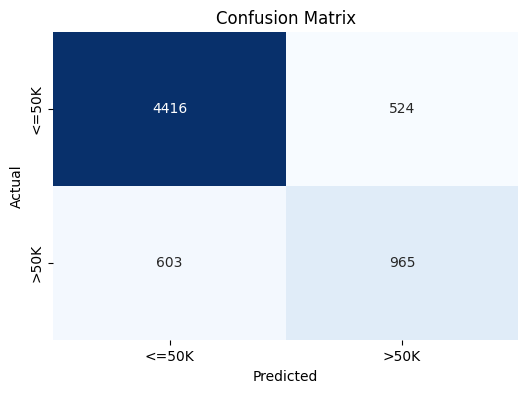


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.88      0.89      0.89      4940
        >50K       0.65      0.62      0.63      1568

    accuracy                           0.83      6508
   macro avg       0.76      0.75      0.76      6508
weighted avg       0.82      0.83      0.83      6508

ROC-AUC: 0.8507827346525656


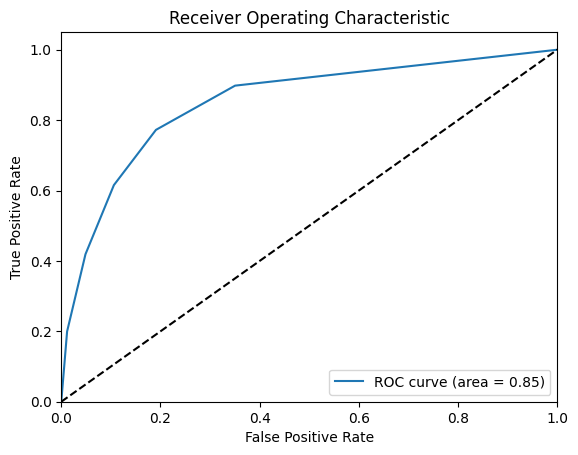

PR AUC: 0.625366515046011


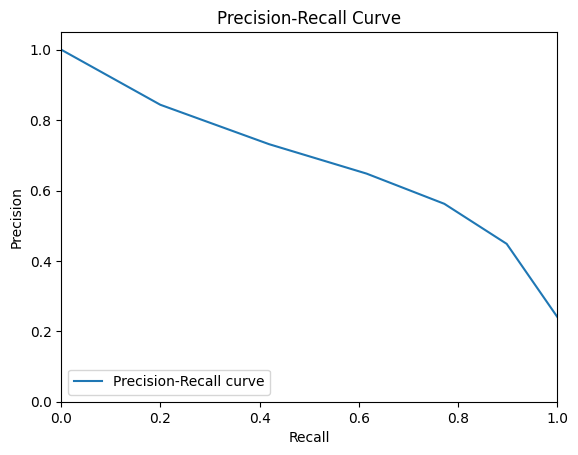

 15%|█▌        | 2/13 [00:15<01:33,  8.53s/it]


Confusion Matrix:
 [[4635  305]
 [ 674  894]]


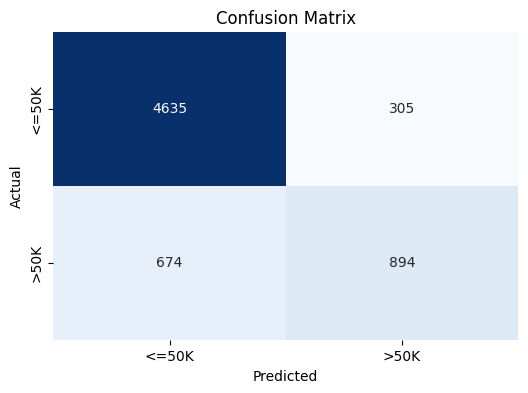


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.87      0.94      0.90      4940
        >50K       0.75      0.57      0.65      1568

    accuracy                           0.85      6508
   macro avg       0.81      0.75      0.78      6508
weighted avg       0.84      0.85      0.84      6508

ROC-AUC: 0.8886199444352638


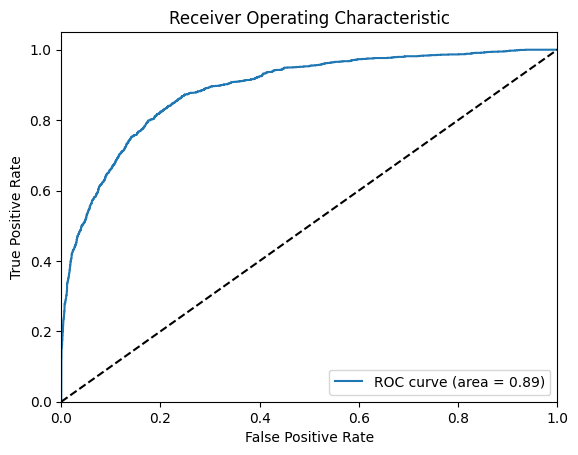

PR AUC: 0.7607725391548464


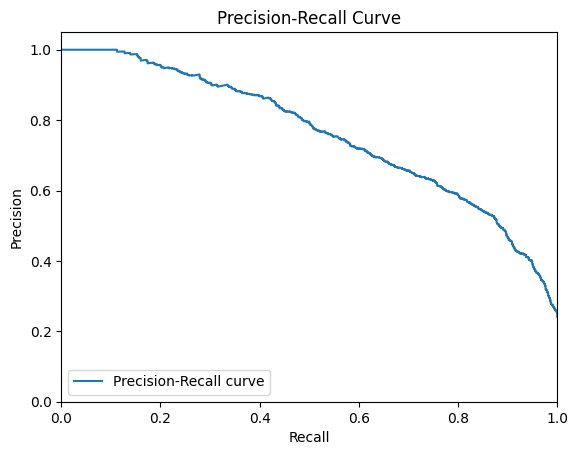

 23%|██▎       | 3/13 [02:54<12:53, 77.35s/it]


Confusion Matrix:
 [[4354  586]
 [ 643  925]]


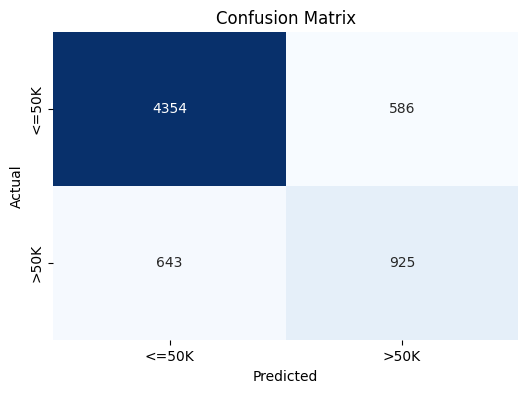


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.87      0.88      0.88      4940
        >50K       0.61      0.59      0.60      1568

    accuracy                           0.81      6508
   macro avg       0.74      0.74      0.74      6508
weighted avg       0.81      0.81      0.81      6508

ROC-AUC: 0.7542335836156325


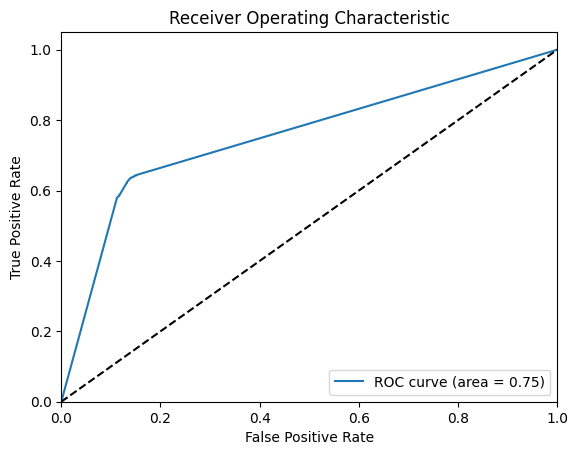

PR AUC: 0.48421726626040185


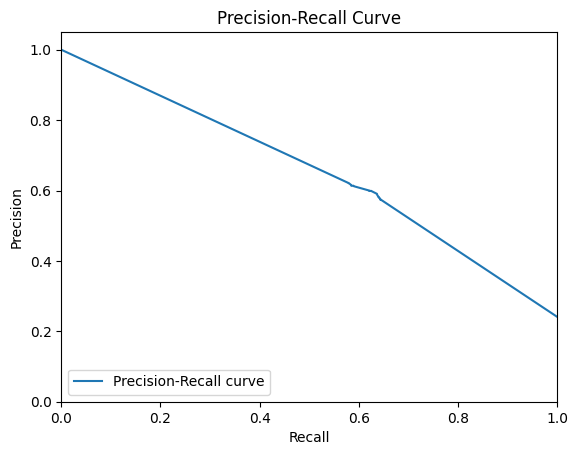

 31%|███       | 4/13 [02:55<07:04, 47.12s/it]


Confusion Matrix:
 [[2241 2699]
 [  89 1479]]


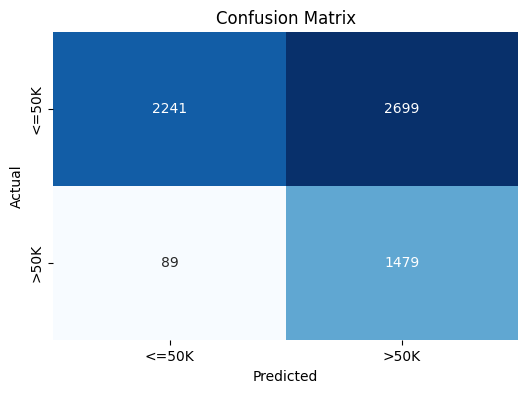


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.96      0.45      0.62      4940
        >50K       0.35      0.94      0.51      1568

    accuracy                           0.57      6508
   macro avg       0.66      0.70      0.57      6508
weighted avg       0.82      0.57      0.59      6508

ROC-AUC: 0.843655304986367


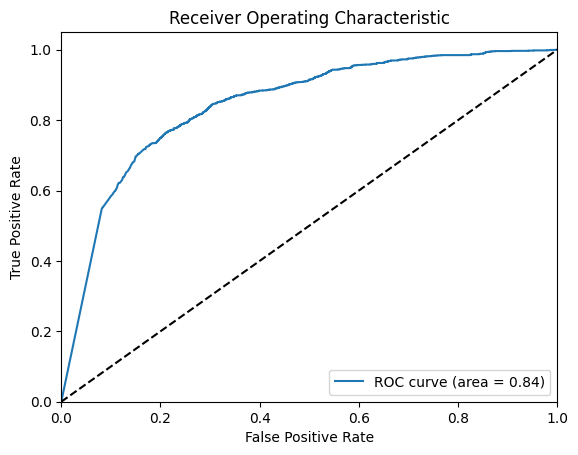

PR AUC: 0.6004273789169446


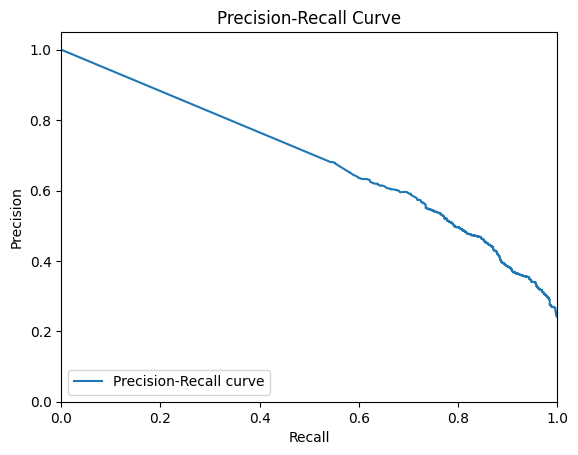

 38%|███▊      | 5/13 [02:56<04:02, 30.36s/it]


Confusion Matrix:
 [[4535  405]
 [ 601  967]]


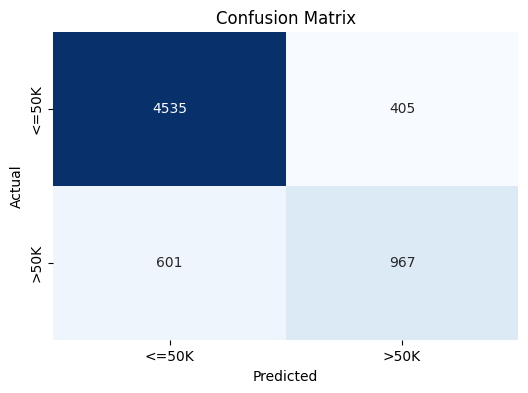


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.88      0.92      0.90      4940
        >50K       0.70      0.62      0.66      1568

    accuracy                           0.85      6508
   macro avg       0.79      0.77      0.78      6508
weighted avg       0.84      0.85      0.84      6508

ROC-AUC: 0.8875288538998595


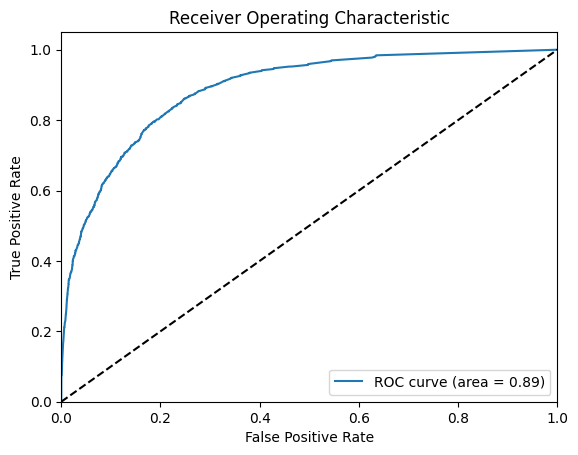

PR AUC: 0.7416022927700364


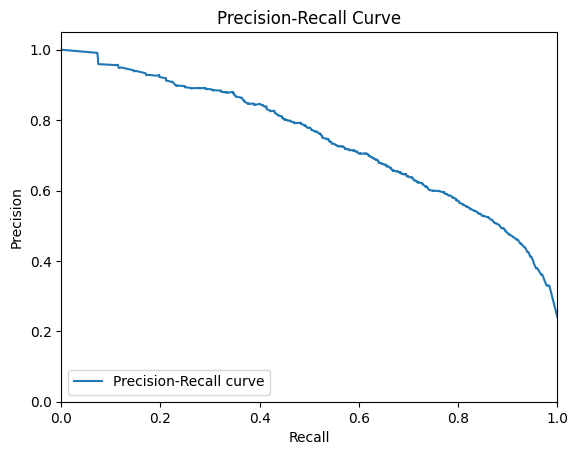

 46%|████▌     | 6/13 [03:00<02:29, 21.40s/it]


Confusion Matrix:
 [[4453  487]
 [ 660  908]]


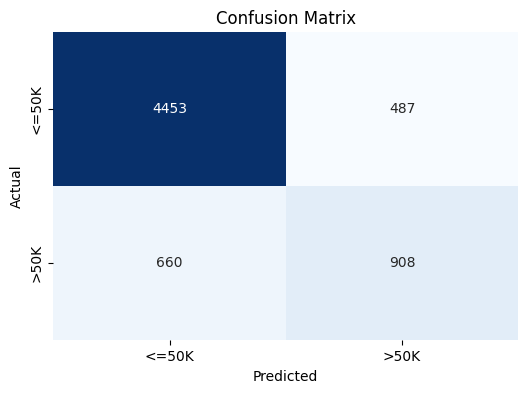


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.87      0.90      0.89      4940
        >50K       0.65      0.58      0.61      1568

    accuracy                           0.82      6508
   macro avg       0.76      0.74      0.75      6508
weighted avg       0.82      0.82      0.82      6508

ROC-AUC: 0.8401856073907297


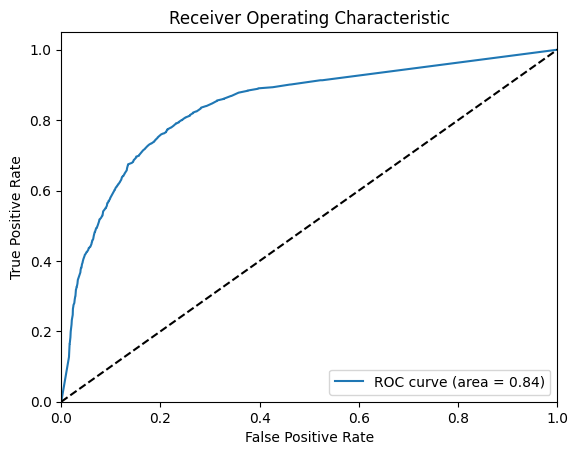

PR AUC: 0.6255092610595798


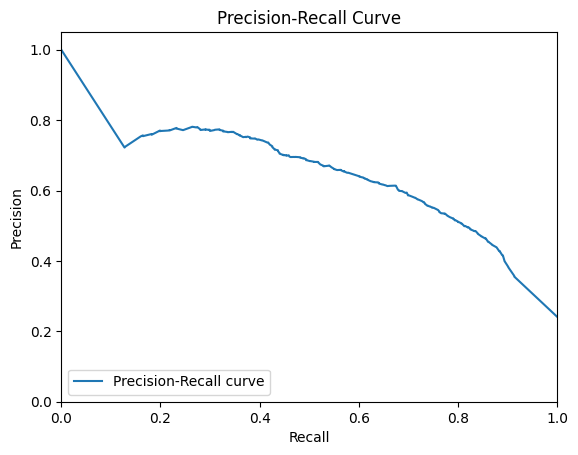

 54%|█████▍    | 7/13 [03:04<01:35, 15.84s/it]


Confusion Matrix:
 [[4668  272]
 [ 720  848]]


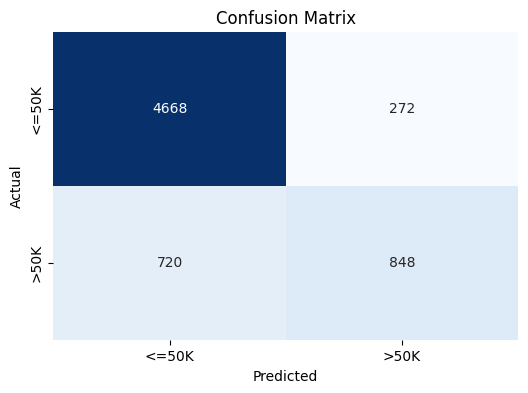


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.87      0.94      0.90      4940
        >50K       0.76      0.54      0.63      1568

    accuracy                           0.85      6508
   macro avg       0.81      0.74      0.77      6508
weighted avg       0.84      0.85      0.84      6508

ROC-AUC: 0.8966397793935388


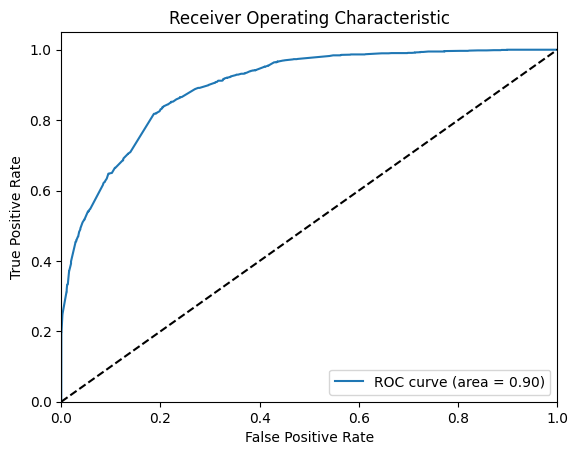

PR AUC: 0.758770283959471


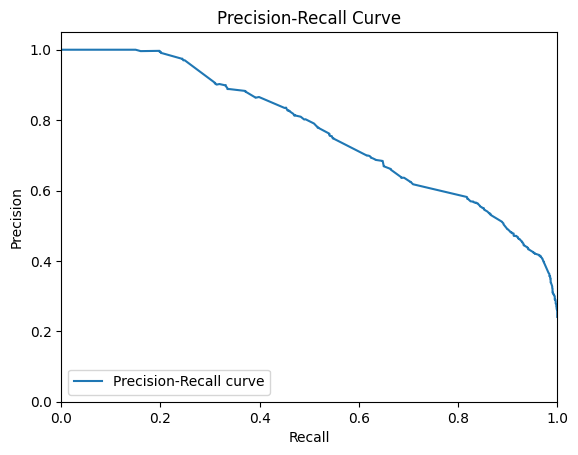

 62%|██████▏   | 8/13 [03:05<00:56, 11.23s/it]


Confusion Matrix:
 [[4684  256]
 [ 638  930]]


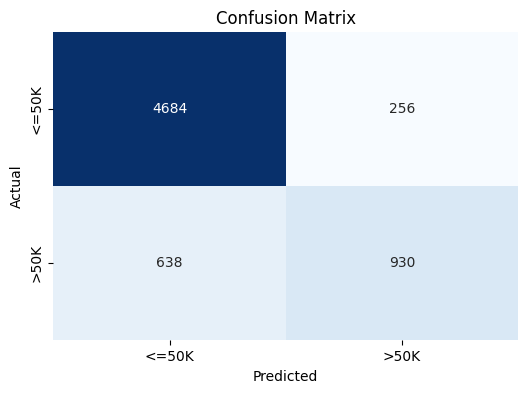


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.88      0.95      0.91      4940
        >50K       0.78      0.59      0.68      1568

    accuracy                           0.86      6508
   macro avg       0.83      0.77      0.79      6508
weighted avg       0.86      0.86      0.86      6508

ROC-AUC: 0.914808053788317


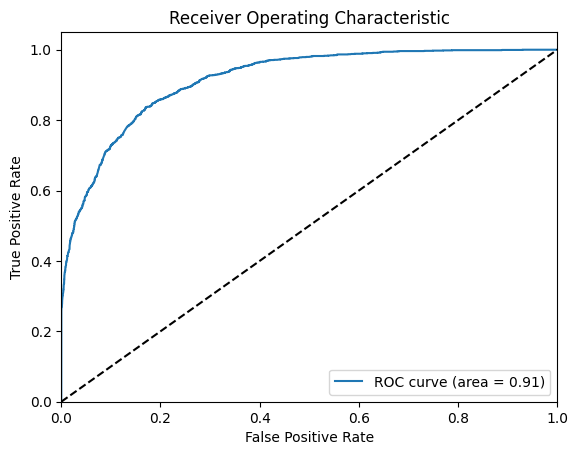

PR AUC: 0.8083365404491752


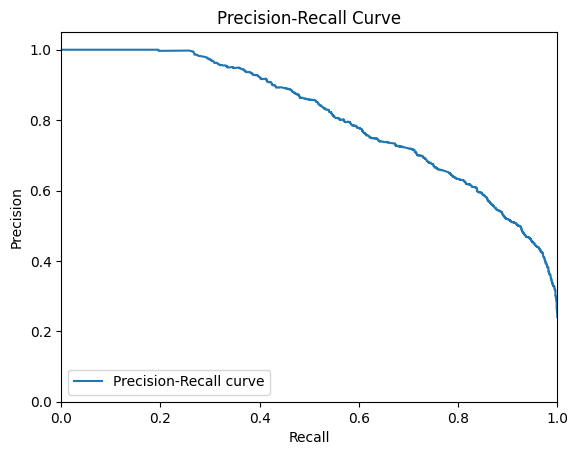

 69%|██████▉   | 9/13 [03:09<00:35,  8.87s/it]


Confusion Matrix:
 [[4632  308]
 [ 553 1015]]


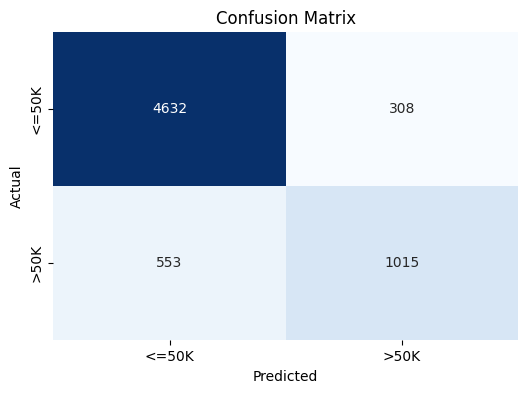


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.89      0.94      0.91      4940
        >50K       0.77      0.65      0.70      1568

    accuracy                           0.87      6508
   macro avg       0.83      0.79      0.81      6508
weighted avg       0.86      0.87      0.86      6508

ROC-AUC: 0.9210423681112121


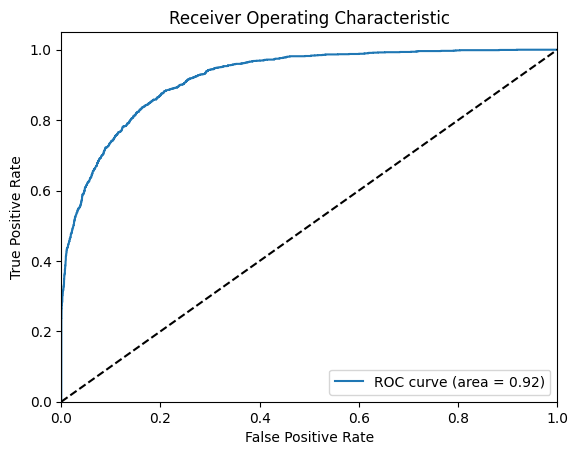

PR AUC: 0.8195361020417354


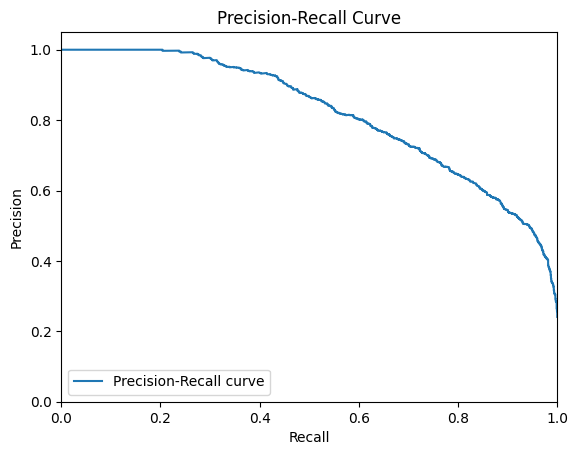

 77%|███████▋  | 10/13 [03:12<00:20,  6.94s/it]


Confusion Matrix:
 [[4630  310]
 [ 544 1024]]


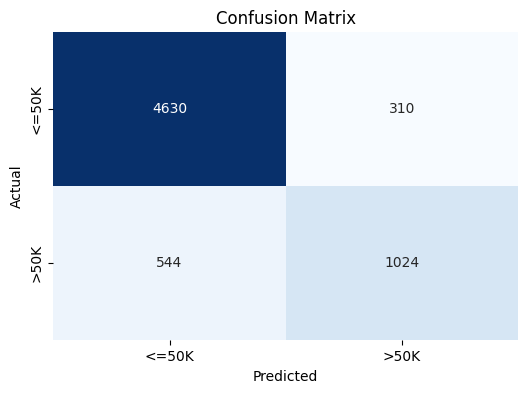


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.89      0.94      0.92      4940
        >50K       0.77      0.65      0.71      1568

    accuracy                           0.87      6508
   macro avg       0.83      0.80      0.81      6508
weighted avg       0.86      0.87      0.87      6508

ROC-AUC: 0.9209810455052467


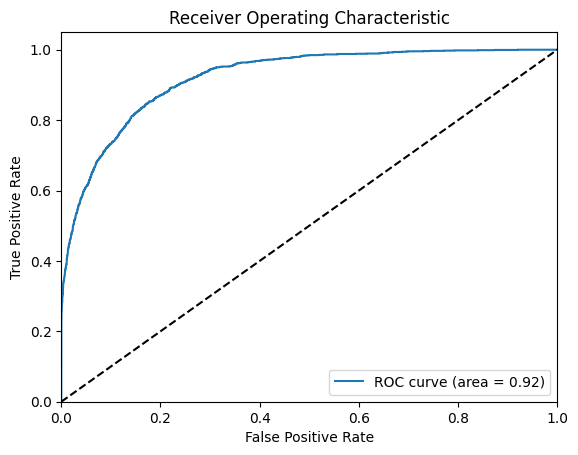

PR AUC: 0.8190517215062854


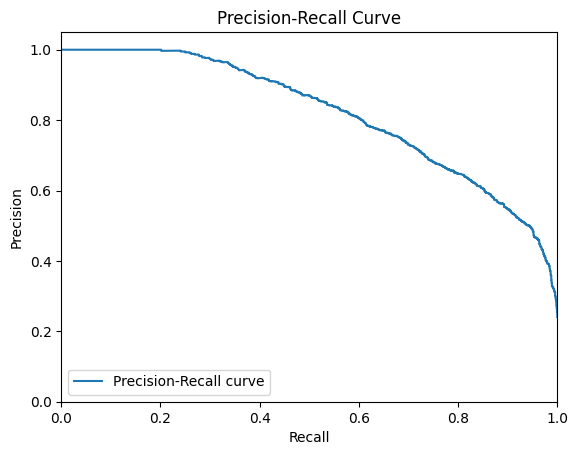

 85%|████████▍ | 11/13 [03:13<00:10,  5.17s/it]


Confusion Matrix:
 [[4653  287]
 [ 546 1022]]


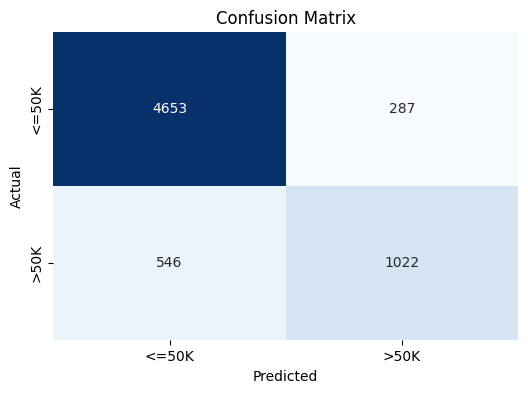


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.89      0.94      0.92      4940
        >50K       0.78      0.65      0.71      1568

    accuracy                           0.87      6508
   macro avg       0.84      0.80      0.81      6508
weighted avg       0.87      0.87      0.87      6508

ROC-AUC: 0.9233907011691316


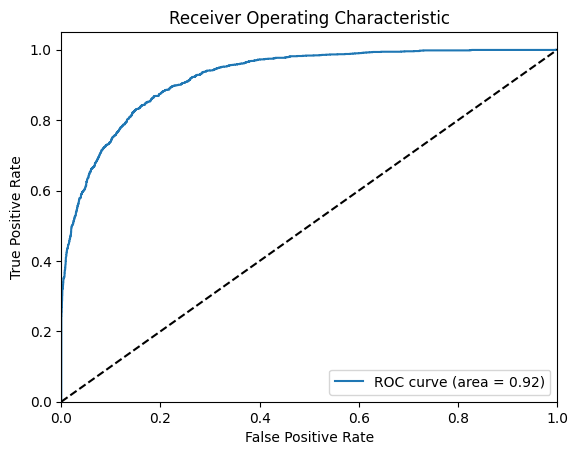

PR AUC: 0.8245931083252769


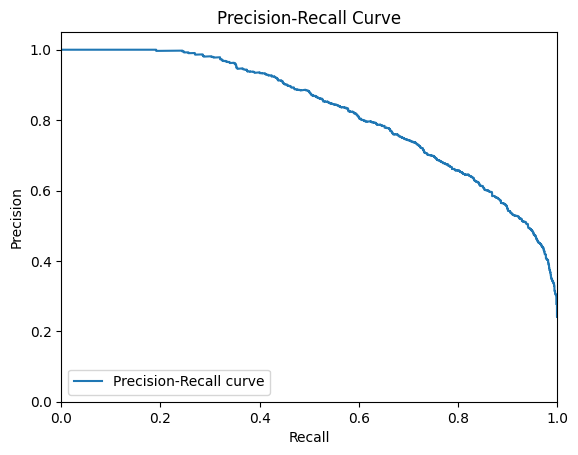

 92%|█████████▏| 12/13 [03:21<00:05,  5.98s/it]

[LightGBM] [Info] Number of positive: 6271, number of negative: 19758
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003736 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 432
[LightGBM] [Info] Number of data points in the train set: 26029, number of used features: 40
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.240924 -> initscore=-1.147623
[LightGBM] [Info] Start training from score -1.147623

Confusion Matrix:
 [[4642  298]
 [ 562 1006]]


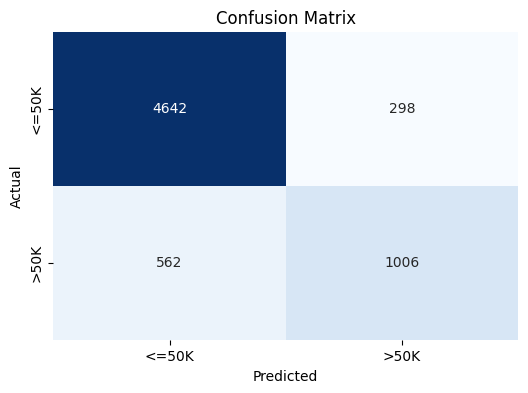


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.89      0.94      0.92      4940
        >50K       0.77      0.64      0.70      1568

    accuracy                           0.87      6508
   macro avg       0.83      0.79      0.81      6508
weighted avg       0.86      0.87      0.86      6508

ROC-AUC: 0.9209304382177973


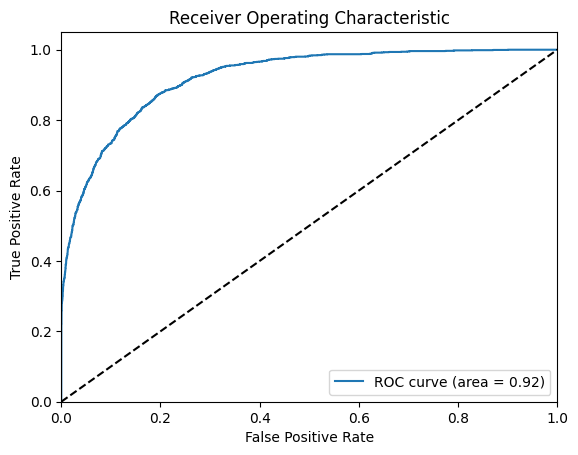

PR AUC: 0.8198453430458347


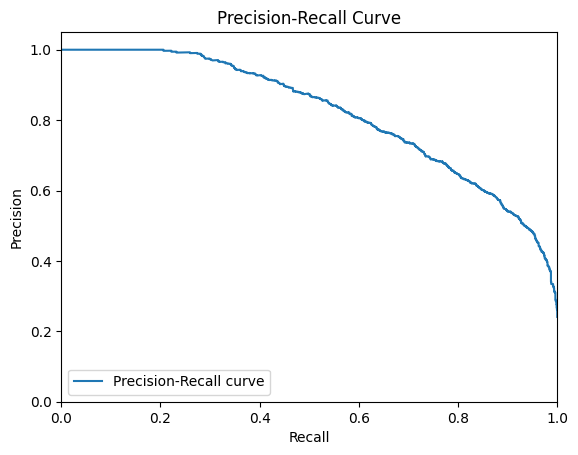

100%|██████████| 13/13 [03:22<00:00, 15.58s/it]


In [43]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)



    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
                xticklabels=['<=50K','>50K']
                ,yticklabels=['<=50K','>50K'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(y_test, test_pred,target_names=['<=50K','>50K'],zero_division=0))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred),
        "Test Precision": precision_score(y_test, test_pred),
        "Train Recall": recall_score(y_train, train_pred),
        "Test Recall": recall_score(y_test, test_pred),
        "Train F1 Score": f1_score(y_train, train_pred),
        "Test F1 Score": f1_score(y_test, test_pred),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc

    }


Confusion Matrix:
 [[4290  650]
 [ 382 1186]]


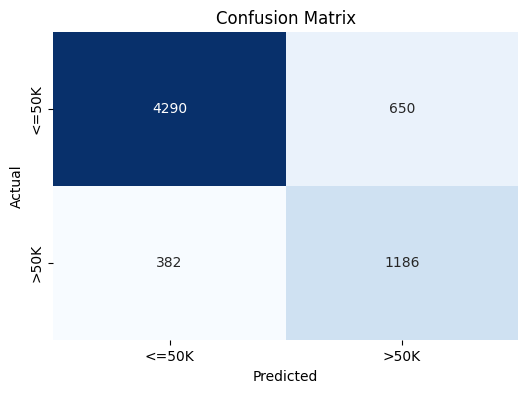


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.92      0.87      0.89      4940
        >50K       0.65      0.76      0.70      1568

    accuracy                           0.84      6508
   macro avg       0.78      0.81      0.79      6508
weighted avg       0.85      0.84      0.85      6508

ROC-AUC: 0.9052142934602991


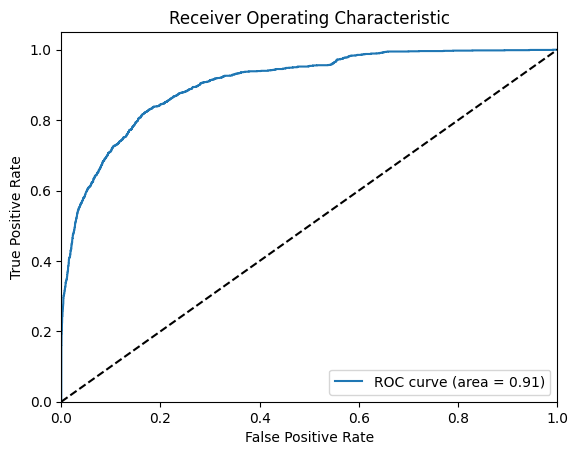

PR AUC: 0.7947929158998249


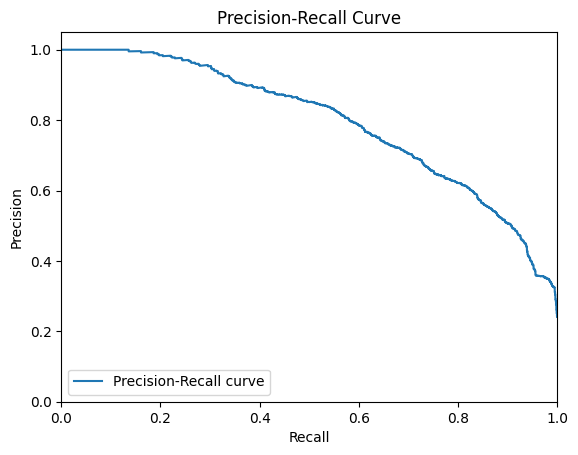

In [44]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(X_train, y_train)
voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['<=50K','>50K']
            ,yticklabels=['<=50K','>50K'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, voting_test_pred,target_names=['<=50K','>50K'],zero_division=0))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred),
    "Test Precision": precision_score(y_test, voting_test_pred),
    "Train Recall": recall_score(y_train, voting_train_pred),
    "Test Recall": recall_score(y_test, voting_test_pred),
    "Train F1 Score": f1_score(y_train, voting_train_pred),
    "Test F1 Score": f1_score(y_test, voting_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}


Confusion Matrix:
 [[4619  321]
 [ 559 1009]]


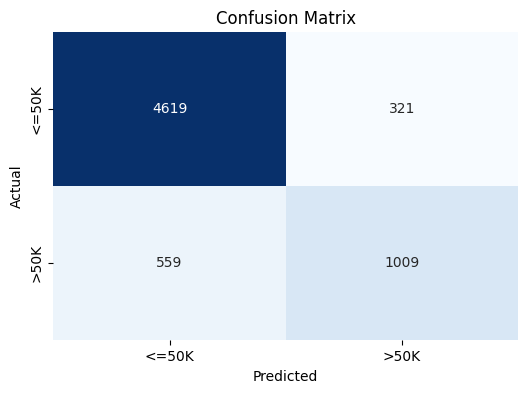


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.89      0.94      0.91      4940
        >50K       0.76      0.64      0.70      1568

    accuracy                           0.86      6508
   macro avg       0.83      0.79      0.80      6508
weighted avg       0.86      0.86      0.86      6508

ROC-AUC: 0.9167589518094688


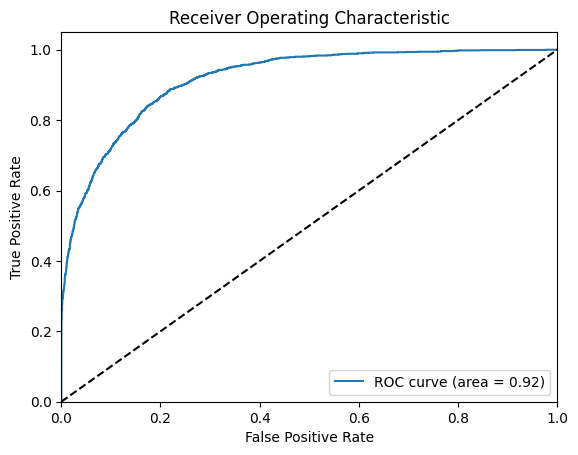

PR AUC: 0.8101889886033563


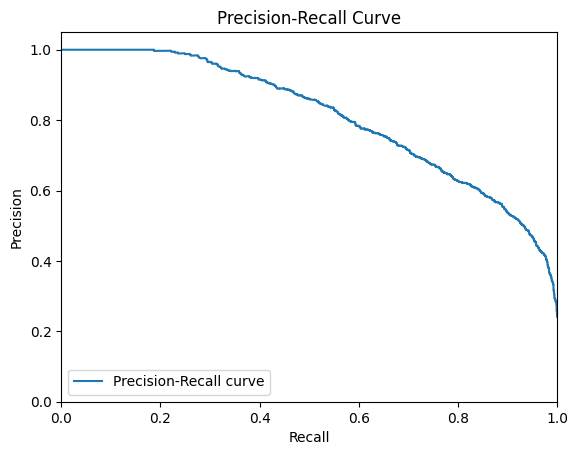

In [45]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),


    ],
    final_estimator=XGBClassifier(eval_metric='logloss', random_state=1),
    stack_method="predict_proba",   # best for classification usually
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt="d",cmap='Blues',cbar=False,
             xticklabels=['<=50K','>50K']
            ,yticklabels=['<=50K','>50K'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(y_test, stack_auto_test_pred,target_names=['<=50K','>50K'],zero_division=0))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier "] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred),
    "Test Precision": precision_score(y_test, stack_auto_test_pred),
    "Train Recall": recall_score(y_train, stack_auto_train_pred),
    "Test Recall": recall_score(y_test, stack_auto_test_pred),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [46]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)

In [47]:
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
CatBoost,0.894771,0.872004,0.829970,0.780749,0.708340,0.651786,0.764347,0.710462,0.831141,0.796844,0.923391,0.824593
XGBoost,0.898383,0.868777,0.834255,0.767616,0.721576,0.653061,0.773835,0.705720,0.838037,0.795154,0.920981,0.819052
Hist Gradient Boosting,0.885897,0.867701,0.807757,0.767196,0.690799,0.647321,0.744714,0.702179,0.819309,0.792487,0.921042,0.819536
LightGBM,0.887087,0.867855,0.812805,0.771472,0.690321,0.641582,0.746572,0.700557,0.819930,0.790629,0.920930,0.819845
Voting Classifier,0.915172,0.841426,0.778631,0.645969,0.905278,0.756378,0.837192,0.696827,0.911795,0.812399,0.905214,0.794793
Stacking Classifier,0.892312,0.864782,0.817466,0.758647,0.712008,0.643495,0.761101,0.696342,0.830774,0.789258,0.916759,0.810189
Gradient Boosting,0.871105,0.862631,0.798404,0.784148,0.622070,0.593112,0.699292,0.675381,0.786108,0.770645,0.914808,0.808337
Random Forest,0.979369,0.845421,0.966482,0.704810,0.947217,0.616709,0.956753,0.657823,0.968396,0.767363,0.887529,0.741602
Logistic Regression,0.845480,0.844960,0.716708,0.714835,0.593047,0.593112,0.649040,0.648310,0.759324,0.759006,0.895342,0.737139
SVC,0.864689,0.849570,0.777733,0.745621,0.613778,0.570153,0.686096,0.646187,0.779052,0.754206,0.888620,0.760773


<Axes: >

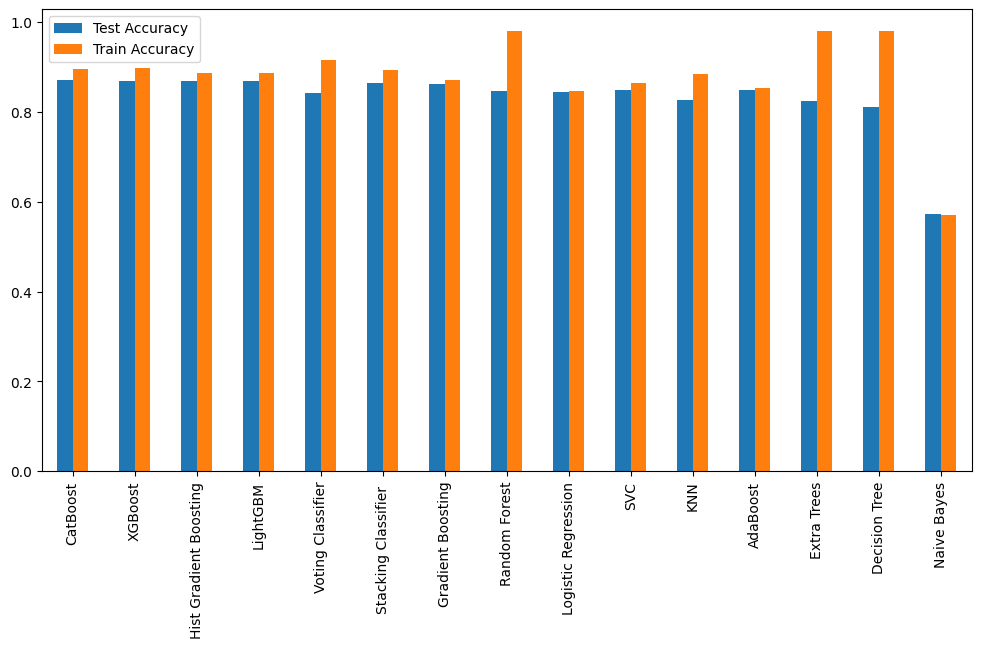

In [48]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

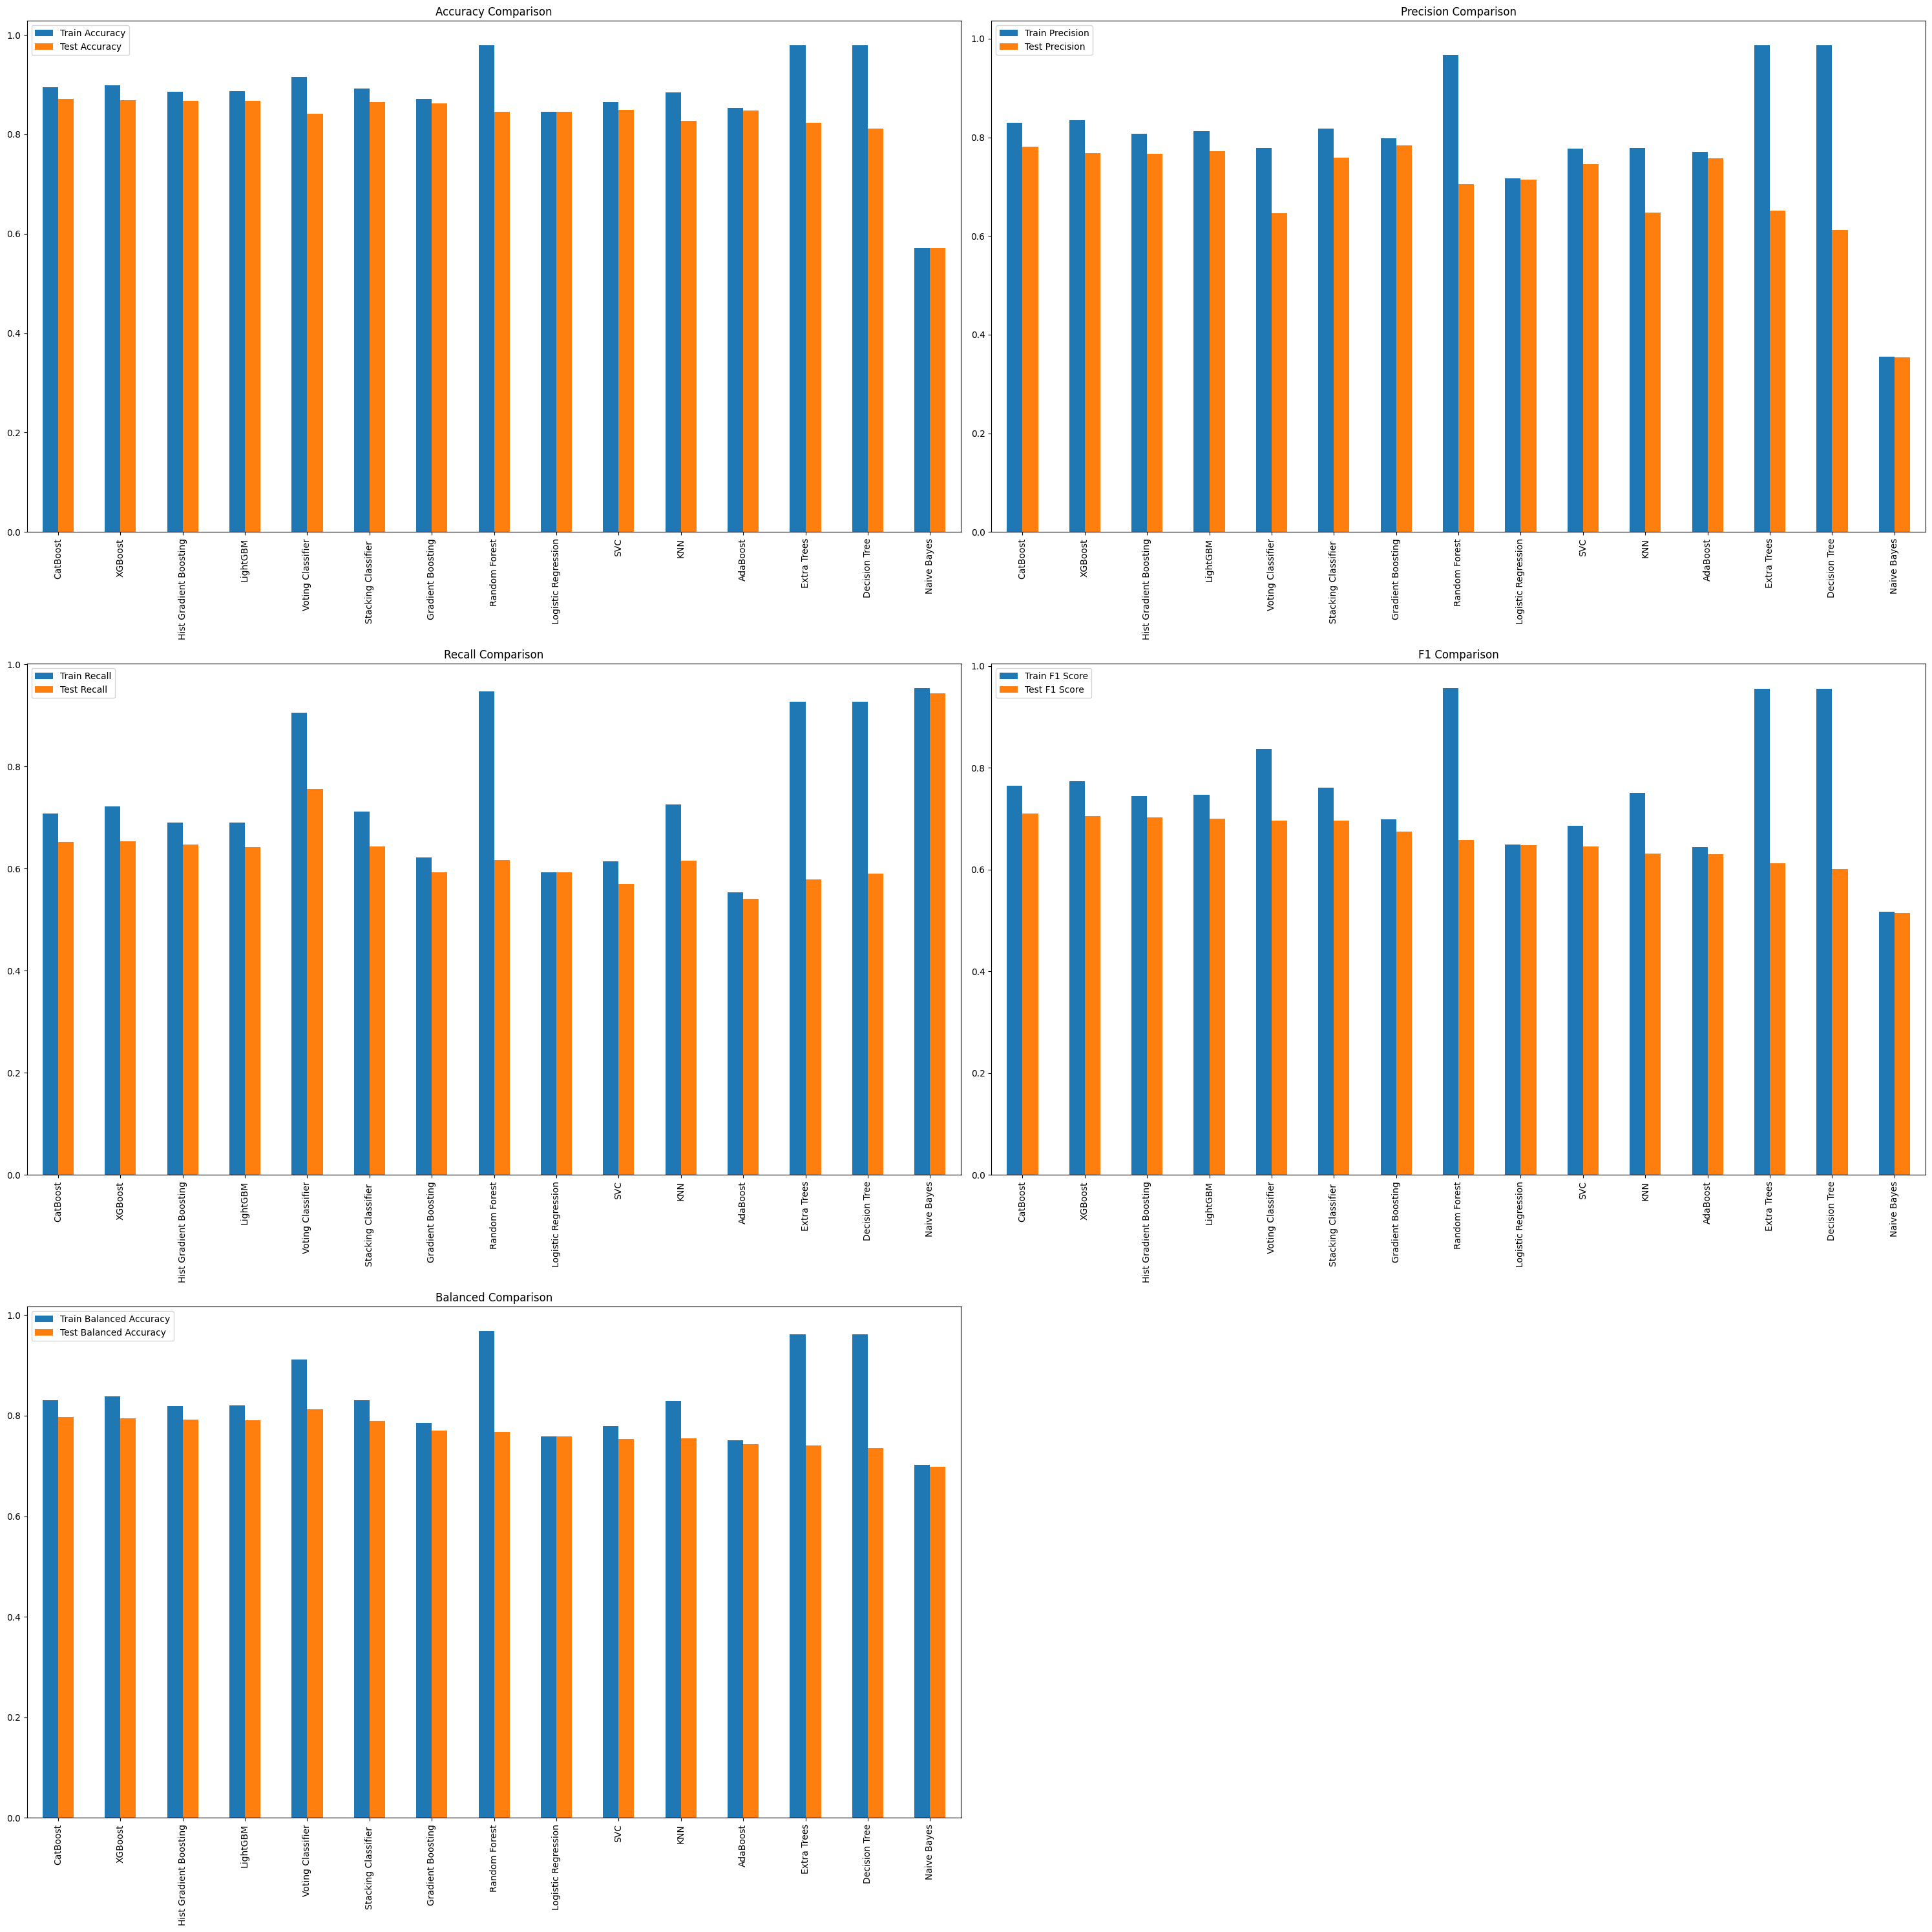

In [49]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()

**Note:** this table uses the test set to show how each model behaves with the default threshold. To **choose** and **tune** the model we do not use the test set: we use cross-validation on the training data (next sections).

## 8. Model comparison with Cross-Validation (train data only)
5-fold stratified cross-validation on the training data. Metric: **PR-AUC (average precision)**, a good metric for an imbalanced target; a random model gets ~0.24. (`SVC` is used without `probability=True` inside the CV only to save time; the ranking by `decision_function` gives the same PR-AUC idea.)

In [50]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.base import clone

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores = {}
for name, model in tqdm(models.items()):
    m = SVC(random_state=1) if name == "SVC" else model
    scores = cross_val_score(m, X_train, y_train, cv=skf, scoring='average_precision', n_jobs=-1)
    cv_scores[name] = scores.mean()

cv_df = pd.Series(cv_scores).sort_values(ascending=False).to_frame('CV PR-AUC')
print("Random-guess PR-AUC:", round(y_train.mean(), 3))
cv_df

 85%|████████▍ | 11/13 [02:05<00:12,  6.33s/it]/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
 92%|█████████▏| 12/13 [02:38<00:14, 14.24s/it]/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
100%|██████████| 13/13 [02:43<00:00, 12.55s/it]

Random-guess PR-AUC: 0.241


,CV PR-AUC
CatBoost,0.831455
LightGBM,0.831121
Hist Gradient Boosting,0.829103
XGBoost,0.828723
Gradient Boosting,0.817236
SVC,0.769680
AdaBoost,0.764901
Random Forest,0.757914
Logistic Regression,0.740748
Extra Trees,0.656632


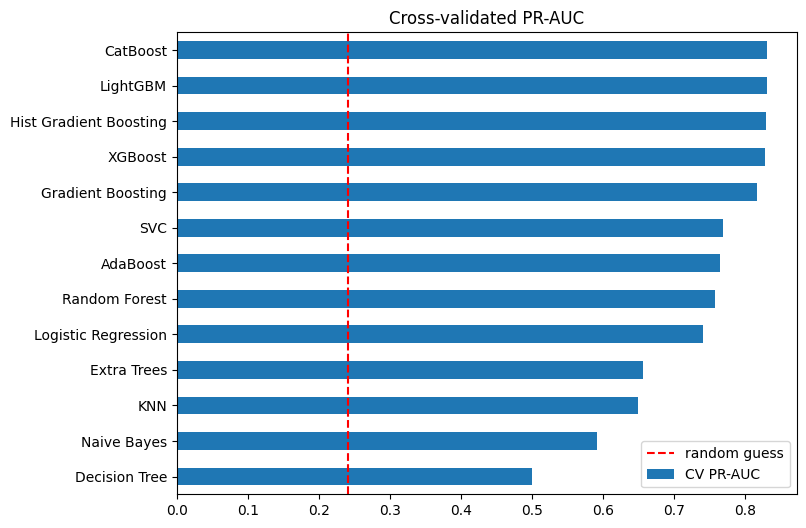

In [51]:
cv_df['CV PR-AUC'].sort_values().plot.barh(figsize=(8, 6))
plt.axvline(y_train.mean(), color='red', linestyle='--', label='random guess')
plt.title('Cross-validated PR-AUC')
plt.legend()
plt.show()

## 9. GridSearchCV on the best 3 models
The top 3 models of the cross-validation comparison are tuned with `GridSearchCV` (5-fold, metric PR-AUC, training data only). `class_weight` is part of the grid when the model supports it.

In [52]:
param_grids = {
    'Logistic Regression': {'C': [0.01, 0.1, 1, 10], 'class_weight': [None, 'balanced']},
    'KNN': {'n_neighbors': [5, 11, 21, 41], 'weights': ['uniform', 'distance']},
    'SVC': {'C': [0.5, 1, 5], 'class_weight': [None, 'balanced']},
    'Decision Tree': {'max_depth': [5, 8, 12], 'min_samples_leaf': [5, 20, 50], 'class_weight': [None, 'balanced']},
    'Naive Bayes': {'var_smoothing': [1e-9, 1e-7, 1e-5, 1e-3]},
    'Random Forest': {'max_depth': [10, 20, None], 'min_samples_leaf': [1, 5, 10], 'class_weight': [None, 'balanced_subsample']},
    'Extra Trees': {'max_depth': [10, 20, None], 'min_samples_leaf': [1, 5, 10], 'class_weight': [None, 'balanced_subsample']},
    'AdaBoost': {'n_estimators': [50, 100, 200], 'learning_rate': [0.1, 0.5, 1.0]},
    'Gradient Boosting': {'n_estimators': [100, 200], 'learning_rate': [0.05, 0.1], 'max_depth': [3, 5]},
    'Hist Gradient Boosting': {'learning_rate': [0.03, 0.1], 'max_depth': [3, None], 'class_weight': [None, 'balanced']},
    'XGBoost': {'n_estimators': [100, 300], 'max_depth': [3, 5], 'learning_rate': [0.03, 0.1]},
    'CatBoost': {'iterations': [300, 600], 'depth': [4, 6], 'learning_rate': [0.03, 0.1]},
    'LightGBM': {'n_estimators': [100, 300], 'num_leaves': [15, 31], 'learning_rate': [0.03, 0.1]},
}

top3 = cv_df.head(3).index.tolist()
print("Models to tune:", top3)

tuned = {}
summary = []
for name in top3:
    m = SVC(random_state=1) if name == "SVC" else models[name]
    grid = GridSearchCV(m, param_grids[name], cv=skf, scoring='average_precision', n_jobs=-1)
    grid.fit(X_train, y_train)
    tuned[name] = grid
    print(f"\n{name}")
    print("  best_params_:", grid.best_params_)
    print("  best_score_ :", round(grid.best_score_, 4))
    summary.append([name, cv_df.loc[name, 'CV PR-AUC'], grid.best_score_])

tuning_df = pd.DataFrame(summary, columns=['Model', 'Before tuning (CV PR-AUC)', 'After tuning (best_score_)']).set_index('Model')
tuning_df

Models to tune: ['CatBoost', 'LightGBM', 'Hist Gradient Boosting']


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



CatBoost
  best_params_: {'depth': 4, 'iterations': 600, 'learning_rate': 0.1}
  best_score_ : 0.8321


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


[LightGBM] [Info] Number of positive: 6271, number of negative: 19758
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002558 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 432
[LightGBM] [Info] Number of data points in the train set: 26029, number of used features: 40
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.240924 -> initscore=-1.147623
[LightGBM] [Info] Start training from score -1.147623

LightGBM
  best_params_: {'learning_rate': 0.1, 'n_estimators': 100, 'num_leaves': 31}
  best_score_ : 0.8311

Hist Gradient Boosting
  best_params_: {'class_weight': None, 'learning_rate': 0.1, 'max_depth': None}
  best_score_ : 0.8291


,Before tuning (CV PR-AUC),After tuning (best_score_)
Model,,
CatBoost,0.831455,0.832065
LightGBM,0.831121,0.831121
Hist Gradient Boosting,0.829103,0.829103


**Why these parameters:** depth / leaf size / `C` control the complexity (overfitting vs underfitting); `learning_rate` and the number of trees trade off in boosting; `class_weight='balanced'` gives more importance to the `>50K` class; `n_neighbors` controls the smoothness of KNN.

## 10. Final model and decision threshold
The best tuned model (highest `best_score_`) is refitted on the train data. The decision threshold is chosen on **cross-validated predictions of the training data** (the one that maximizes F1), not on the test set.

In [53]:
best_name = tuning_df['After tuning (best_score_)'].idxmax()
best_model = clone(tuned[best_name].best_estimator_)
print("Best model:", best_name, tuned[best_name].best_params_)

oof_proba = cross_val_predict(best_model, X_train, y_train, cv=skf, method='predict_proba', n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best_thr = float(thr[np.argmax(f1s)])
print("Chosen threshold:", round(best_thr, 3))

best_model.fit(X_train, y_train)

Best model: CatBoost {'depth': 4, 'iterations': 600, 'learning_rate': 0.1}
Chosen threshold: 0.371


CatBoostClassifier(depth=4, iterations=600, learning_rate=0.1, random_state=1, verbose=0)

## 11. Final evaluation on the test set (used once)

--- Classification Report (tuned threshold) ---
              precision    recall  f1-score   support

       <=50K       0.92      0.90      0.91      4940
        >50K       0.70      0.75      0.72      1568

    accuracy                           0.86      6508
   macro avg       0.81      0.82      0.82      6508
weighted avg       0.87      0.86      0.86      6508

Accuracy: 0.862 | ROC-AUC: 0.923 | PR-AUC: 0.822 | random PR-AUC: 0.241


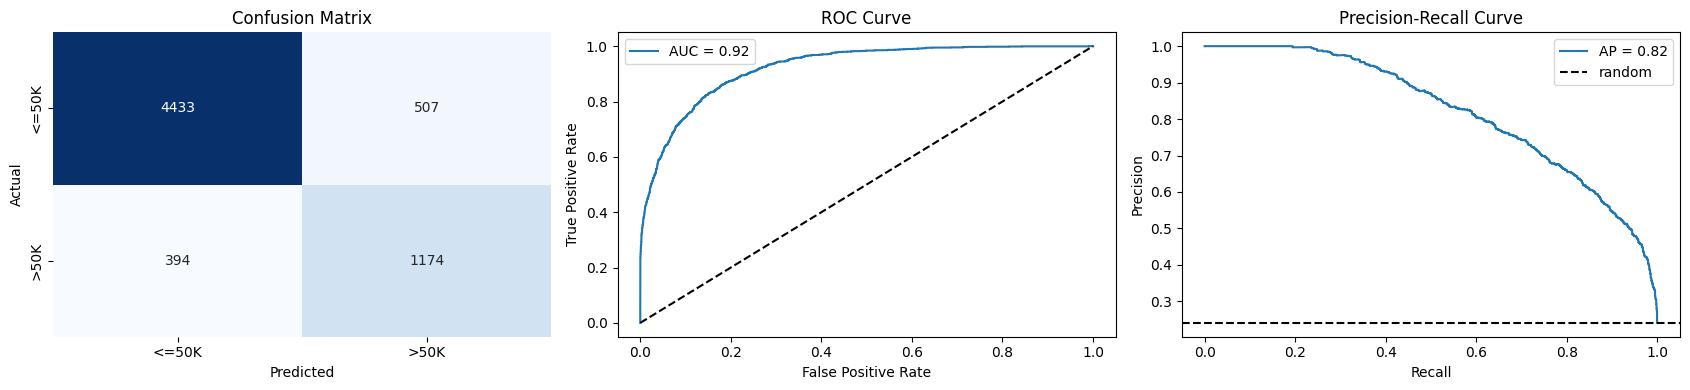

In [54]:
test_proba = best_model.predict_proba(X_test)[:, 1]
y_final = (test_proba >= best_thr).astype(int)

print("--- Classification Report (tuned threshold) ---")
print(classification_report(y_test, y_final, target_names=['<=50K', '>50K'], zero_division=0))

roc_auc = roc_auc_score(y_test, test_proba)
pr_auc = average_precision_score(y_test, test_proba)
print("Accuracy:", round(accuracy_score(y_test, y_final), 3), "| ROC-AUC:", round(roc_auc, 3), "| PR-AUC:", round(pr_auc, 3), "| random PR-AUC:", round(y_test.mean(), 3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
cm = confusion_matrix(y_test, y_final)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['<=50K', '>50K'], yticklabels=['<=50K', '>50K'])
axes[0].set_title('Confusion Matrix'); axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

fpr, tpr, _ = roc_curve(y_test, test_proba)
axes[1].plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}'); axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_title('ROC Curve'); axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate'); axes[1].legend()

p_, r_, _ = precision_recall_curve(y_test, test_proba)
axes[2].plot(r_, p_, label=f'AP = {pr_auc:.2f}'); axes[2].axhline(y_test.mean(), color='k', linestyle='--', label='random')
axes[2].set_title('Precision-Recall Curve'); axes[2].set_xlabel('Recall'); axes[2].set_ylabel('Precision'); axes[2].legend()
plt.tight_layout()
plt.show()

In [55]:
tn, fp, fn, tp = cm.ravel()
print("=== Automatic interpretation of the results ===")
print(f"- Model: {best_name} | threshold: {best_thr:.2f}")
print(f"- Finds {tp} of {tp + fn} people who earn >50K (recall = {tp / (tp + fn):.0%}) and misses {fn}.")
print(f"- Of {tp + fp} people predicted as >50K, {tp} really are (precision = {tp / max(tp + fp, 1):.0%}).")
print(f"- Accuracy = {accuracy_score(y_test, y_final):.1%} (a model that always says '<=50K' would get {1 - y_test.mean():.1%}).")
print(f"- ROC-AUC = {roc_auc:.2f}, PR-AUC = {pr_auc:.2f} (random guessing = {y_test.mean():.2f}).")

=== Automatic interpretation of the results ===
- Model: CatBoost | threshold: 0.37
- Finds 1174 of 1568 people who earn >50K (recall = 75%) and misses 394.
- Of 1681 people predicted as >50K, 1174 really are (precision = 70%).
- Accuracy = 86.2% (a model that always says '<=50K' would get 75.9%).
- ROC-AUC = 0.92, PR-AUC = 0.82 (random guessing = 0.24).


**Interpretation**
- **Accuracy** must be compared with the 76% of the "always `<=50K`" model; the real gain is in recall and PR-AUC.
- **Recall (>50K)** = how many high earners we find; **Precision (>50K)** = how many of our "high earner" predictions are right. The threshold moves the balance between the two.
- **Confusion matrix:** FP = low earners wrongly predicted high, FN = high earners we miss.
- **ROC-AUC** shows the ranking quality over all thresholds; **PR-AUC** is stricter because it ignores the many easy true negatives and is compared with the random line (~0.24).
- This is a binary problem, so no multiclass averaging is needed.
- **Limits:** the data is a 1994 US census, so the model describes that population and should not be used to judge real people today; `sex` and `race` are in the data, which would be a fairness problem in a real product.

## 12. Conclusions
- Unknown values (`?`) became a category instead of being guessed; imputation and scaling are fitted on the train data only.
- The imbalance was handled with SMOTE / under-sampling / class weights and judged with Recall, F1, ROC-AUC and PR-AUC, not only Accuracy.
- The model was chosen with cross-validation, tuned with `GridSearchCV`, the threshold chosen on training data, and the test set was used once.
- Possible improvements: group rare countries, feature engineering (e.g. `capital.gain > 0`), more tuning.